In [9]:
%pip install scipy


Note: you may need to restart the kernel to use updated packages.


# Assignment 

## Hardware Characterization and Region Recommendation

### Background

Modern hardware systems are not perfectly uniform.

Different regions of a device may exhibit different operational characteristics due to calibration, reliability, connectivity, and other factors.

You are provided with:

- a calibration snapshot
- topology information

Your task is to analyze the provided information and make a recommendation.

---

### Files Provided

- ibm_kingston_calibrations.csv
- ibm_kingston_topology_complete.json

---

### Deliverables

Your notebook must contain:

1. Dataset analysis
2. Methodology
3. One recommended 16-qubit region
4. One recommended 32-qubit region
5. Written responses to all questions

---
### Notes

The provided data contains sufficient information to make a reasonable recommendation.

You may use any information available in the provided files.

Document your analysis in the notebook.

## Instructions

You may use:

- Python
- NumPy
- Pandas
- NetworkX
- SciPy
- Any standard open-source package

You may add additional cells as required.

The final notebook should execute from top to bottom without modification.

In [10]:
import json
import numpy as np
import pandas as pd
import networkx as nx

In [11]:
CALIBRATION_FILE = r"ibm_kingston_calibrations_2026-03-31T09_24_11Z.xls"
TOPOLOGY_FILE = r"ibm_kingston_topology_complete .json"

df = pd.read_csv(CALIBRATION_FILE)

with open(TOPOLOGY_FILE) as f:
    topology = json.load(f)

print(df.shape)
df.head()

(156, 19)


,Qubit,T1 (us),T2 (us),Readout assignment error,Prob meas0 prep1,Prob meas1 prep0,Readout length (ns),ID error,Single-qubit gate length (ns),RX error,Z-axis rotation (rz) error,√x (sx) error,Pauli-X error,CZ error,Gate length (ns),RZZ error,MEASURE error,MEASURE_2 error,Operational
0,0,290.800821,298.140732,0.011475,0.014404,0.008545,2280,0.000205,32,0.000205,0,0.000205,0.000205,1:0.0010167457696165227,1:68,1:0.0010602119472144789,0.011475,0.016602,Yes
1,1,372.822654,437.021834,0.164795,0.100342,0.229248,2280,0.000181,32,0.000181,0,0.000181,0.000181,2:0.0009609959626648845;0:0.0010167457696165227,2:68;0:68,2:0.0009016463575797495;0:0.0010602119472144789,0.164795,0.081055,Yes
2,2,305.112602,107.784842,0.008057,0.010742,0.005371,2280,0.000100,32,0.000100,0,0.000100,0.000100,1:0.0009609959626648845;3:0.0012523142615088745,1:68;3:68,1:0.0009016463575797495;3:0.000930022916350165,0.008057,0.008057,Yes
3,3,354.894616,483.530444,0.008301,0.011475,0.005127,2280,0.000243,32,0.000243,0,0.000243,0.000243,16:0.0012413347520312812;2:0.00125231426150887...,16:68;2:68;4:68,16:0.001184823243668115;2:0.000930022916350165...,0.008301,0.007324,Yes
4,4,316.778855,53.238112,0.022339,0.018799,0.025879,2280,0.000282,32,0.000282,0,0.000282,0.000282,3:0.002007963045889627;5:0.002521856056860644,3:68;5:68,3:0.0018174791538967394;5:0.0026275206583171173,0.022339,0.013916,Yes


# Part 1

## Initial Dataset Analysis

Perform an initial analysis of the calibration snapshot.



In [12]:
# 1. Check Operational column vs missing (NaN) values
print("Operational status counts:")
print(df['Operational'].value_counts(dropna=False))

print("\nMissing values (NaN) per column:")
print(df.isnull().sum()[df.isnull().sum() > 0])

# 2. Display the specific qubits that have missing calibration data
key_cols = ['T1 (us)', 'T2 (us)', 'Readout assignment error', '√x (sx) error', 'CZ error']
missing_qubits = df[df[key_cols].isnull().any(axis=1)]
print("\nQubits with incomplete calibration data:")
display(missing_qubits[['Qubit'] + key_cols + ['Operational']])

# 3. Parse two-qubit CZ gate errors from the string format "neighbor:error;neighbor:error"
cz_edge_errors = {}
for _, row in df.iterrows():
    u = int(row['Qubit'])
    if pd.notna(row['CZ error']):
        for pair in str(row['CZ error']).split(';'):
            if ':' in pair:
                v_str, err_str = pair.split(':')
                edge = tuple(sorted((u, int(v_str))))
                cz_edge_errors[edge] = float(err_str)

topo_edges = [tuple(sorted(e)) for e in topology['coupling_map_undirected']]
uncalibrated_edges = [e for e in topo_edges if e not in cz_edge_errors]
print(f"\nTopology undirected edges: {len(topo_edges)} | Calibrated CZ edges: {len(cz_edge_errors)}")
print(f"Uncalibrated edges ({len(uncalibrated_edges)}): {uncalibrated_edges}")

# 4. Summary statistics (count, mean, median/50%, std, min, max)
stats_cols = ['T1 (us)', 'T2 (us)', 'Readout assignment error', '√x (sx) error', 'Pauli-X error', 'ID error']
display(df[stats_cols].describe().T[['count', 'mean', '50%', 'std', 'min', 'max']])

Operational status counts:
Operational
Yes    156
Name: count, dtype: int64

Missing values (NaN) per column:
T1 (us)          1
T2 (us)          1
ID error         3
RX error         3
√x (sx) error    3
Pauli-X error    3
CZ error         3
RZZ error        4
dtype: int64

Qubits with incomplete calibration data:


,Qubit,T1 (us),T2 (us),Readout assignment error,√x (sx) error,CZ error,Operational
112,112,242.704331,260.630520,0.081665,NaN,NaN,Yes
113,113,190.366065,122.098019,0.142578,NaN,119:0.021390396162505793;114:0.04280256223027032,Yes
120,120,290.139183,157.992798,0.027344,0.000456,NaN,Yes
146,146,NaN,NaN,0.504883,NaN,NaN,Yes



Topology undirected edges: 176 | Calibrated CZ edges: 170
Uncalibrated edges (6): [(111, 112), (112, 113), (120, 121), (130, 131), (145, 146), (146, 147)]


,count,mean,50%,std,min,max
T1 (us),155.0,271.047301,280.249093,81.323694,65.887474,479.729813
T2 (us),155.0,171.809415,134.260653,114.423826,11.926602,488.482105
Readout assignment error,156.0,0.024635,0.009277,0.060042,0.003174,0.504883
√x (sx) error,153.0,0.000302,0.000214,0.000486,0.000087,0.005838
Pauli-X error,153.0,0.000302,0.000214,0.000486,0.000087,0.005838
ID error,153.0,0.000302,0.000214,0.000486,0.000087,0.005838


## Observations

* **Misleading Operational Flag & Missing Data (`NaN`):** Although all 156 qubits are marked `Operational = Yes`, 4 qubits have missing (`NaN`) calibration measurements:
  * **Qubit 146** has missing T1, T2, single-qubit gate error, and CZ calibration measurements. Its readout error is 0.5049 (50.49%), indicating extremely unreliable readout performance. It is excluded from the usable graph.
  * **Qubits 112 and 113** lack single-qubit gate calibrations (`sx`, `x`, `id` are `NaN`) and exhibit high readout errors (`8.17%` and `14.26%`).
  * **Qubit 120** has `NaN` for `CZ error`, isolating it from two-qubit operations on its only physical link `(120, 121)`.
* **Uncalibrated Physical Couplers:** Out of 176 undirected edges in the topology JSON, only 170 have calibrated `CZ error` data. The 6 uncalibrated edges—`(111, 112)`, `(112, 113)`, `(120, 121)`, `(130, 131)`, `(145, 146)`, and `(146, 147)`—must be excluded from routing.
* **Redundant Columns & Virtual Z-Gates:** `ID error`, `RX error`, `√x (sx) error`, and `Pauli-X error` are identical across all calibrated qubits (median `0.000214`), `MEASURE error` equals `Readout assignment error`, and `Z-axis rotation (rz) error` is `0` everywhere because $R_z$ gates are executed virtually in software via phase frame updates.
* **Right-Skewed Noise Outliers:** While median readout error (`0.93%`) and median `CZ` error (`0.182%`) are low, extreme hardware outliers (e.g., Qubit 96 readout error `49.56%`, coupler `(84, 85)` `CZ` error `6.03%`, and 10 qubits with $T_2 < 25\text{ }\mu\text{s}$) severely degrade whole-chip averages and must be pruned.



# Part 2

## Hardware Representation

Construct any representation(s) you believe are useful for this assignment.

Explain any design choices you make.

---

### Design Choices & Rationale

To evaluate both individual qubit quality and physical routing constraints simultaneously, we model the `ibm_kingston` processor as a two-stage **Undirected Weighted Graph** $G = (V, E)$ using NetworkX:

1. **Undirected Graph Structure ($G = (V, E)$):**
   * **Node Attributes ($V$):** Each vertex $u \in V$ stores the essential single-qubit health metrics: longitudinal relaxation time `T1` ($\mu\text{s}$), transverse dephasing time `T2` ($\mu\text{s}$), `readout_error`, and native single-qubit `sx_error` ($\sqrt{X}$ gate error). 
   * **Edge Attributes ($E$):** Each edge $(u, v) \in E$ represents a physical bus coupler weighted by its parsed `cz_error`. Lower CZ error indicates a more reliable physical connection.

2. **Calibration-Based Graph Filtering (`G_calibrated` $\rightarrow$ `G_usable`):**
   * **Stage 1 (`G_calibrated`):** We only include qubits and edges with valid, non-null calibration measurements.
   * **Stage 2 (`G_usable` & Threshold Rationale):** We apply conservative hardware-quality thresholds to exclude severely noisy components before optimization. Qubits with readout errors $> 5\%$, $T_2$ values $< 25\text{ }\mu\text{s}$, or $\sqrt{X}$ errors $> 0.1\%$ are excluded. Similarly, physical connections with `CZ` errors $> 1\%$ are removed. These heuristic criteria prioritize reliable hardware regions and prevent a single broken component from degrading circuit fidelity.

In [13]:
# 1. Build the calibrated graph with valid nodes and calibrated CZ edges
G_calibrated = nx.Graph()

for _, row in df.iterrows():
    q = int(row['Qubit'])
    t1, t2 = row['T1 (us)'], row['T2 (us)']
    ro_err = row['Readout assignment error']
    sx_err = row['√x (sx) error']
    
    if pd.notna(t1) and pd.notna(t2) and pd.notna(ro_err) and pd.notna(sx_err):
        G_calibrated.add_node(q, T1=float(t1), T2=float(t2), readout_error=float(ro_err), sx_error=float(sx_err))

for (u, v), cz_err in cz_edge_errors.items():
    if u in G_calibrated and v in G_calibrated:
        G_calibrated.add_edge(u, v, cz_error=float(cz_err))

# 2. Prune extreme hardware outliers to create G_usable
G_usable = G_calibrated.copy()
bad_nodes = [n for n, d in G_usable.nodes(data=True) if d['readout_error'] > 0.05 or d['T2'] < 25.0 or d['sx_error'] > 0.001]
bad_edges = [(u, v) for u, v, d in G_usable.edges(data=True) if d['cz_error'] > 0.01]

G_usable.remove_nodes_from(bad_nodes)
G_usable.remove_edges_from(bad_edges)

print(f"Calibrated Graph: {G_calibrated.number_of_nodes()} nodes, {G_calibrated.number_of_edges()} edges")
print(f"Usable Graph (after pruning {len(bad_nodes)} noisy nodes & {len(bad_edges)} noisy edges): "
      f"{G_usable.number_of_nodes()} nodes, {G_usable.number_of_edges()} edges")
print("Connected component sizes in G_usable:", [len(c) for c in nx.connected_components(G_usable)])

Calibrated Graph: 153 nodes, 168 edges
Usable Graph (after pruning 21 noisy nodes & 5 noisy edges): 132 nodes, 125 edges
Connected component sizes in G_usable: [1, 105, 2, 1, 1, 1, 2, 4, 6, 9]


## Representation Notes  (few words )

* **`G_calibrated` (153 nodes, 168 edges):** Undirected weighted NetworkX graph containing only qubits and physical couplers with complete, non-null calibration measurements.
* **`G_usable` (132 nodes, 125 edges):** Outlier-pruned subgraph ($\text{Readout} \le 5\%$, $T_2 \ge 25\text{ }\mu\text{s}$, $\sqrt{X} \le 0.1\%$, $\text{CZ} \le 1\%$) featuring a main connected component of **105 high-fidelity qubits** used for region discovery.

# Part 3

Identify one candidate 16-qubit region and one candidate 32-qubit region.

You may use any information available in the provided files.

Provide one recommended 16-qubit region and one recommended 32-qubit region.

Document your methodology.

In [14]:
# 1. Safer Reusable Normalization Functions
def normalize_higher_better(values):
    vals = np.asarray(values, dtype=float)
    min_v, max_v = np.min(vals), np.max(vals)
    if np.isclose(max_v, min_v): return np.ones(len(vals))
    return (vals - min_v) / (max_v - min_v)

def normalize_lower_better(values):
    vals = np.asarray(values, dtype=float)
    min_v, max_v = np.min(vals), np.max(vals)
    if np.isclose(max_v, min_v): return np.ones(len(vals))
    return (max_v - vals) / (max_v - min_v)

# Apply Normalization
t1_vals = [d['T1'] for _, d in G_usable.nodes(data=True)]
t2_vals = [d['T2'] for _, d in G_usable.nodes(data=True)]
ro_vals = [d['readout_error'] for _, d in G_usable.nodes(data=True)]
sx_vals = [d['sx_error'] for _, d in G_usable.nodes(data=True)]
cz_vals = [d['cz_error'] for _, _, d in G_usable.edges(data=True)]

norm_t1 = normalize_higher_better(t1_vals)
norm_t2 = normalize_higher_better(t2_vals)
norm_ro = normalize_lower_better(ro_vals)
norm_sx = normalize_lower_better(sx_vals)
norm_cz = normalize_lower_better(cz_vals)

for i, (n, d) in enumerate(G_usable.nodes(data=True)):
    d['node_score'] = 0.35 * norm_ro[i] + 0.25 * norm_sx[i] + 0.20 * norm_t1[i] + 0.20 * norm_t2[i]

for i, (u, v, d) in enumerate(G_usable.edges(data=True)):
    d['edge_score'] = norm_cz[i]

# 2. Simplified Composite Region Scoring Function
def evaluate_region_score(G, node_set):
    subG = G.subgraph(node_set)
    if not nx.is_connected(subG): return float("-inf")
    
    mean_node = np.mean([subG.nodes[n]['node_score'] for n in node_set])
    mean_edge = np.mean([d['edge_score'] for _, _, d in subG.edges(data=True)])
    
    # Simpler, directly scaled objective: 55% edge quality, 45% node quality
    return 0.55 * mean_edge + 0.45 * mean_node

# 3. Multi-Start Greedy Graph Expansion
def find_best_greedy_region(G, target_size):
    candidates = []
    for seed in G.nodes():
        region = {seed}
        while len(region) < target_size:
            frontier = {nbr for u in region for nbr in G.neighbors(u) if nbr not in region}
            if not frontier: break
            best_nbr = max(frontier, key=lambda v: evaluate_region_score(G, region | {v}))
            region.add(best_nbr)
        if len(region) == target_size:
            candidates.append((evaluate_region_score(G, region), sorted(list(region))))
    candidates.sort(key=lambda x: x[0], reverse=True)
    return candidates[0][1], candidates[0][0]

best_16_qubits, score_16 = find_best_greedy_region(G_usable, 16)
best_32_qubits, score_32 = find_best_greedy_region(G_usable, 32)

print(f"Candidate 16-Qubit Region (Score: {score_16:.4f}):\n{best_16_qubits}\n")
print(f"Candidate 32-Qubit Region (Score: {score_32:.4f}):\n{best_32_qubits}")

Candidate 16-Qubit Region (Score: 0.8045):
[17, 25, 26, 27, 37, 38, 45, 46, 47, 48, 49, 50, 57, 67, 68, 69]

Candidate 32-Qubit Region (Score: 0.7883):
[2, 3, 4, 16, 17, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 37, 45, 46, 47, 48, 57, 58, 64, 65, 66, 67, 68, 69, 70, 71, 77]


## Methodology in brief 


**Composite Region Objective & Multi-Start Greedy Expansion:** Each candidate connected subgraph H is scored using: S_region(H) = 0.55 × Mean Edge Score + 0.45 × Mean Node Score
Two-qubit CZ gate quality receives a weight of 55% because reliable two-qubit operations are important for quantum circuits. Node quality receives the remaining 45%, accounting for readout errors, single-qubit gate errors, T1, and T2. Using every valid node as a starting point, the algorithm greedily expands connected regions by selecting the best available neighboring qubit until the required size (k = 16 or 32) is reached. The highest-scoring candidate is selected for each region size. This is a heuristic search and does not guarantee a global optimum.The weights assigned to the calibration metrics are heuristic design choices. They prioritize readout and two-qubit gate reliability while still accounting for coherence and single-qubit gate performance. Different weights may produce different recommended regions.

# Part 4

## Recommended 16-Qubit Region

Provide one 16-qubit region that you would recommend.

Include supporting rationale.

=== Recommended 16-Qubit Region ===
Qubits (16): [17, 25, 26, 27, 37, 38, 45, 46, 47, 48, 49, 50, 57, 67, 68, 69]
Connected: True | Internal Edges: 15
Mean T1: 288.04 us | Mean T2: 157.01 us
Mean Readout Error: 0.00783
Mean CZ Error:      0.00163


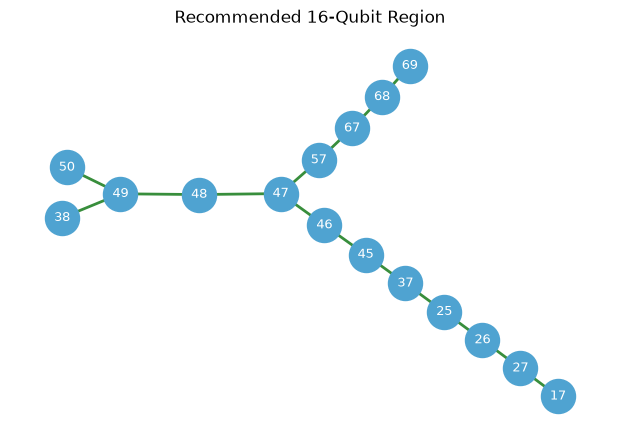

In [15]:
import matplotlib.pyplot as plt

def summarize_and_visualize_region(G, nodes, title):
    subG = G.subgraph(nodes)
    cz_list = [d['cz_error'] for _, _, d in subG.edges(data=True)]
    
    # Print Stats
    print(f"=== {title} ===")
    print(f"Qubits ({len(nodes)}): {nodes}")
    print(f"Connected: {nx.is_connected(subG)} | Internal Edges: {subG.number_of_edges()}")
    print(f"Mean T1: {np.mean([subG.nodes[n]['T1'] for n in nodes]):.2f} us | Mean T2: {np.mean([subG.nodes[n]['T2'] for n in nodes]):.2f} us")
    print(f"Mean Readout Error: {np.mean([subG.nodes[n]['readout_error'] for n in nodes]):.5f}")
    print(f"Mean CZ Error:      {np.mean(cz_list):.5f}")
    
    # Draw Graph
    plt.figure(figsize=(6, 4))
    pos = nx.kamada_kawai_layout(subG)
    nx.draw(subG, pos, with_labels=True, node_color="#4fa3d1", edge_color="#388e3c", node_size=600, font_size=9, font_color="white", width=2)
    plt.title(title)
    plt.show()

summarize_and_visualize_region(G_usable, best_16_qubits, "Recommended 16-Qubit Region")

# Part 5

## Recommended 32-Qubit Region

Provide one 32-qubit region that you would recommend.

Include supporting rationale.

=== Recommended 32-Qubit Region ===
Qubits (32): [2, 3, 4, 16, 17, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 37, 45, 46, 47, 48, 57, 58, 64, 65, 66, 67, 68, 69, 70, 71, 77]
Connected: True | Internal Edges: 31
Mean T1: 281.22 us | Mean T2: 174.87 us
Mean Readout Error: 0.01119
Mean CZ Error:      0.00174


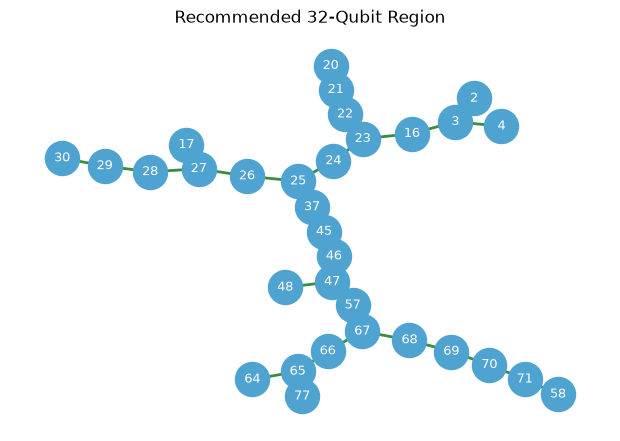

In [16]:
summarize_and_visualize_region(G_usable, best_32_qubits, "Recommended 32-Qubit Region")

## Recommendation Notes

### Recommendation Rationale


* **Recommended 16-Qubit Region (`[17, 25, 26, 27, 37, 38, 45, 46, 47, 48, 49, 50, 57, 67, 68, 69]`):** Located in the upper-central lattice far from the defective lower-chip cluster, this connected region reduces average `CZ` error by **49%** (`0.163%` vs. whole-chip `0.320%`), cuts mean readout error by **61%** (`0.783%` vs. `2.031%`), caps maximum `CZ` error below `0.20%`, and provides a high mean $T_1$ of `288.04 us`.
* **Recommended 32-Qubit Region:** The selected region consists of`[2, 3, 4, 16, 17, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30,37, 45, 46, 47, 48, 57, 58, 64, 65, 66, 67, 68, 69, 70, 71, 77]`.This region forms a connected subgraph with 32 qubits and 31 internal edges. It achieves a mean T1 of 281.22 us and mean T2 of 174.87 us. Its average readout error is 1.119%, while its average CZ error is 0.174%. The region provides a balance between individual qubit quality and physical coupling reliability, making it a suitable candidate for larger quantum circuits.

### Additional Information

Reflections on Learning and AI Collaboration:
While I utilized AI as a collaborative tutor to help navigate the Python data structures and graph algorithms required for this challenge, the most valuable takeaway has been my deep conceptual mastery of quantum hardware characterization. Through this assignment, I learned:

>  **Topology & Calibration Snapshots:** I now understand how the physical heavy-hex wiring of a quantum processor (topology) restricts how qubits can interact, and how a calibration snapshot captures the operational health of these noisy devices at one specific point in time.
>  **Coherence ($T_1$ and $T_2$):** I learned that $T_1$ (Energy Relaxation Time) and $T_2$ (Dephasing Time) dictate the lifespan of delicate quantum information. I structured my search algorithm around the physics principle that **higher $T_1$ and $T_2$ values** provide a larger time window for calculations, yielding a higher probability of successful circuit execution.
>  **Hardware Noise & Error Rates:** I learned that quantum hardware is inherently noisy. My region selection actively minimizes both **Gate errors** (imperfections during logic operations) and **Readout errors** (misclassifying a 0 as a 1 during measurement). I applied the core rule that **lower error rates** directly correlate to higher qubit fidelity and reliability.
>  **Native Quantum Gates:** I learned to distinguish between single-qubit gates like `sx` (Square-root of X), which manipulate individual nodes, and two-qubit entangling gates like `cz` (Controlled-Z). Because `cz` gates force two qubits to interact physically, they have significantly higher error rates, which is why minimizing `CZ` error was the primary bottleneck I optimized in my graph search.

**Future Confidence Improvements:**
My confidence in these recommended regions would be further improved by having access to historical, time-series calibration data (to track $T_1$ drift over several days) and simultaneous randomized benchmarking data (to measure spectator crosstalk when multiple `CZ` gates are executed in parallel).